#3 - Data Integrity & Leakage-Free 5-Fold Cross-Validation Split


## Phase 1 Deliverables Overview
This notebook addresses all core requirements for **Phase 1: Prepare reliable evidence**:
1. **Source Identity & Duplicate Audit:** Identify duplicate pairs and consecutive exam frames.
2. **Leakage-Free Partitioning:** Generate a frozen 5-fold cross-validation split folds.csv using StratifiedGroupKFold.
3. **Anatomical Mask Verification:** Inspect `.mat` kidney masks and overlay them onto ultrasound images.
4. **Lesion Box Coordinate Verification:** Inspect bounding boxes annotations and overlay them on pathological images.

In [1]:
import os
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
# Corregir el directorio para que apunte a la raíz del proyecto
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
# 1. Load the classification manifests y duplicate pairs of images
manifest_path = 'results/eda/classification_manifest.csv' if os.path.exists('results/eda/classification_manifest.csv') else 'classification_manifest.csv'
duplicates_path = 'results/eda/duplicate_pairs.csv'

df = pd.read_csv(manifest_path)
duplicates = pd.read_csv(duplicates_path)

df['filename'] = df['filename'].astype(str)

# 2. Filter only the real duplicate or the same exam ones from the csv
valid_leakage_pairs = duplicates[
    duplicates['verdict'].isin(['identical image', 'same exam (consecutive frame)'])
]

# 3. Construct the mapping groups
group_mapping = {}
group_counter = 0

for _, row in valid_leakage_pairs.iterrows():
    img_a = str(row['img_a']).strip()
    img_b = str(row['img_b']).strip()

    if not img_a.endswith('.jpg'):
        img_a += '.jpg'
    if not img_b.endswith('.jpg'):
        img_b += '.jpg'

    if img_a in group_mapping:
        gid = group_mapping[img_a]
    elif img_b in group_mapping:
        gid = group_mapping[img_b]
    else:
        gid = f"group_{group_counter}"
        group_counter += 1

    group_mapping[img_a] = gid
    group_mapping[img_b] = gid

# Assing group ID or mantain he archive name if its not a duplicate
df['group_id'] = df['filename'].map(group_mapping).fillna(df['filename'])

# 4. Generate Stratified Group 5-Fold Split
sgkf = StratifiedGroupKFold(n_splits=5)
df['fold'] = -1

for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, df['diagnosis'], df['group_id'])):
    df.loc[val_idx, 'fold'] = fold

# 5. Save manifest frozen with the folds
os.makedirs('results/eda', exist_ok=True)
df.to_csv('results/eda/folds.csv', index=False)

grouped_count = df[df['group_id'].str.startswith('group_')]['group_id'].nunique()
print(f"Successfully created: 'results/eda/folds.csv'.  {grouped_count} clusters of images.")

c:\Users\rpast\OneDrive\Documentos\anaconda\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Successfully created: 'results/eda/folds.csv'.  88 clusters of images.


## Validation & Audit Checks

Sanity checks executed:
1. **Class Balance:** Confirm healthy (0) vs pathological (1) target distribution across folds.
2. **Leakage Audit:** Verify zero `group_id` overlap between training and validation sets.

In [2]:
folds_df = pd.read_csv('results/eda/folds.csv')

print("CLASS DISTRIBUTION PER FOLD (%)")
print(pd.crosstab(folds_df['fold'], folds_df['diagnosis'], normalize='index') * 100)

leakage_found = False
for fold in range(5):
    val_groups = set(folds_df[folds_df['fold'] == fold]['group_id'])
    train_groups = set(folds_df[folds_df['fold'] != fold]['group_id'])

    overlap = val_groups.intersection(train_groups)
    if len(overlap) > 0:
        print(f" There is leakage in fold {fold}: {overlap}")
        leakage_found = True

if not leakage_found:
    print("\n AUDIT PASSED: Zero data leakage detected across all 5 folds.")

CLASS DISTRIBUTION PER FOLD (%)
diagnosis          0          1
fold                           
0          22.670025  77.329975
1          22.670025  77.329975
2          22.727273  77.272727
3          22.727273  77.272727
4          22.556391  77.443609

 AUDIT PASSED: Zero data leakage detected across all 5 folds.


##Verification of duplicates / Near-Duplicates

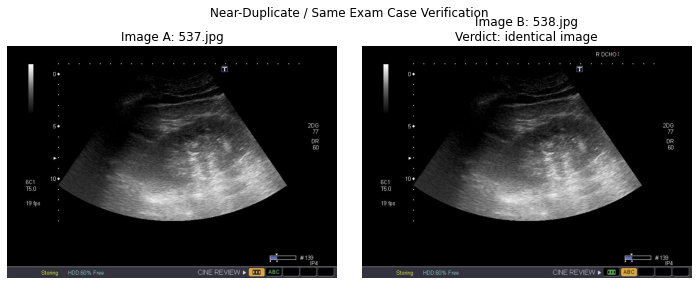

In [3]:
import matplotlib.pyplot as plt
import cv2

# Visualización de casos duplicados / mismo examen (Source identity verification)
if len(valid_leakage_pairs) > 0:
    sample_pair = valid_leakage_pairs.iloc[0]
    img_a_name = str(sample_pair['img_a']).strip()
    img_b_name = str(sample_pair['img_b']).strip()
    if not img_a_name.endswith('.jpg'): img_a_name += '.jpg'
    if not img_b_name.endswith('.jpg'): img_b_name += '.jpg'

    path_a = os.path.join('bbdd_kidney', 'images', img_a_name)
    path_b = os.path.join('bbdd_kidney', 'images', img_b_name)

    if os.path.exists(path_a) and os.path.exists(path_b):
        img_a = cv2.cvtColor(cv2.imread(path_a), cv2.COLOR_BGR2RGB)
        img_b = cv2.cvtColor(cv2.imread(path_b), cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.imshow(img_a)
        plt.title(f"Image A: {img_a_name}")
        plt.axis('off')

        plt.subplot(1, 2, 2)
        plt.imshow(img_b)
        plt.title(f"Image B: {img_b_name}\nVerdict: {sample_pair['verdict']}")
        plt.axis('off')

        plt.suptitle("Near-Duplicate / Same Exam Case Verification", fontsize=12)
        plt.tight_layout()
        plt.show()

Inspection of .mat and Images

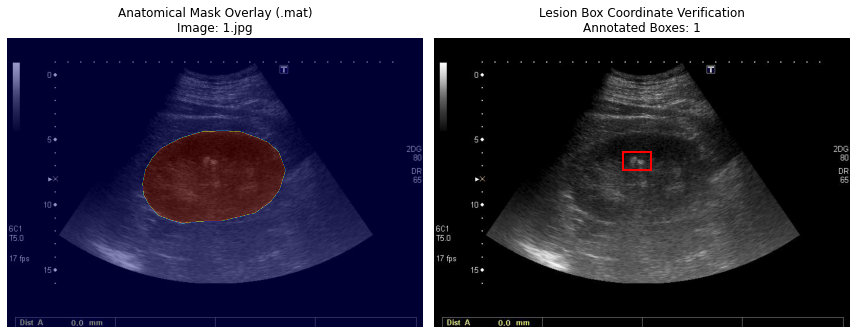

Verified image 1.jpg with 1 lesion bounding box(es).


In [7]:
import os
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 1. Parsear los archivos .txt buscando cualquier variación de "Bounding box"
sample_img_id = None
boxes_for_sample = []

labels_dir = os.path.join('bbdd_kidney', 'labels')
if os.path.exists(labels_dir):
    for label_file in sorted(os.listdir(labels_dir)):
        if label_file.endswith('.txt'):
            path = os.path.join(labels_dir, label_file)
            with open(path, 'r', encoding='utf-8', errors='replace') as f:
                lines = f.readlines()
                current_boxes = []
                for line in lines:
                    line_clean = line.strip()
                    if "bounding box" in line_clean.lower():
                        # Extraer todos los números enteros de la línea
                        import re
                        numbers = [int(n) for n in re.findall(r'\d+', line_clean)]
                        # Si encontramos al menos 5 valores (x, y, w, h, class_id)
                        if len(numbers) >= 5:
                            # Nos quedamos con los últimos 5 enteros de la línea
                            x, y, w, h, cls = numbers[-5:]
                            current_boxes.append((x, y, w, h, cls))
                
                if len(current_boxes) > 0:
                    sample_img_id = label_file.replace('.txt', '')
                    boxes_for_sample = current_boxes
                    break

# 2. Cargar y visualizar la imagen seleccionada
img_name = f"{sample_img_id}.jpg"
img_path = os.path.join('bbdd_kidney', 'images', img_name)
mask_path = os.path.join('bbdd_kidney', 'masks', f"{sample_img_id}.mat")

if os.path.exists(img_path) and os.path.exists(mask_path):
    img = Image.open(img_path).convert('RGB')
    
    # Cargar máscara .mat
    mat_data = sio.loadmat(mask_path)
    valid_keys = [k for k in mat_data.keys() if not k.startswith('__')]
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    
    # Panel 1: Máscara anatómica (.mat)
    ax[0].imshow(img)
    if len(valid_keys) > 0:
        mask_matrix = mat_data[valid_keys[0]]
        ax[0].imshow(mask_matrix, alpha=0.4, cmap='jet')
        ax[0].set_title(f"Anatomical Mask Overlay (.mat)\nImage: {img_name}")
    ax[0].axis('off')
    
    # Panel 2: Verificación de Bounding Boxes de Lesión (.txt)
    ax[1].imshow(img)
    if len(boxes_for_sample) > 0:
        for (x, y, w, h, cls) in boxes_for_sample:
            rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
            ax[1].add_patch(rect)
        ax[1].set_title(f"Lesion Box Coordinate Verification\nAnnotated Boxes: {len(boxes_for_sample)}")
    else:
        ax[1].set_title("Lesion Box Inspection\n(No bounding boxes in label)")
    ax[1].axis('off')
    
    plt.tight_layout()
    plt.show()
    print(f"Verified image {img_name} with {len(boxes_for_sample)} lesion bounding box(es).")
else:
    print(f"Check path: Image or mask missing for {img_name}")

Panel Izquierdo (.mat): La máscara del contorno del riñón pintada en todo el órgano.   Panel Derecho (.txt): La caja del punto patológico o lesión delimitada con la coordenada exacta.

Deliverables together:

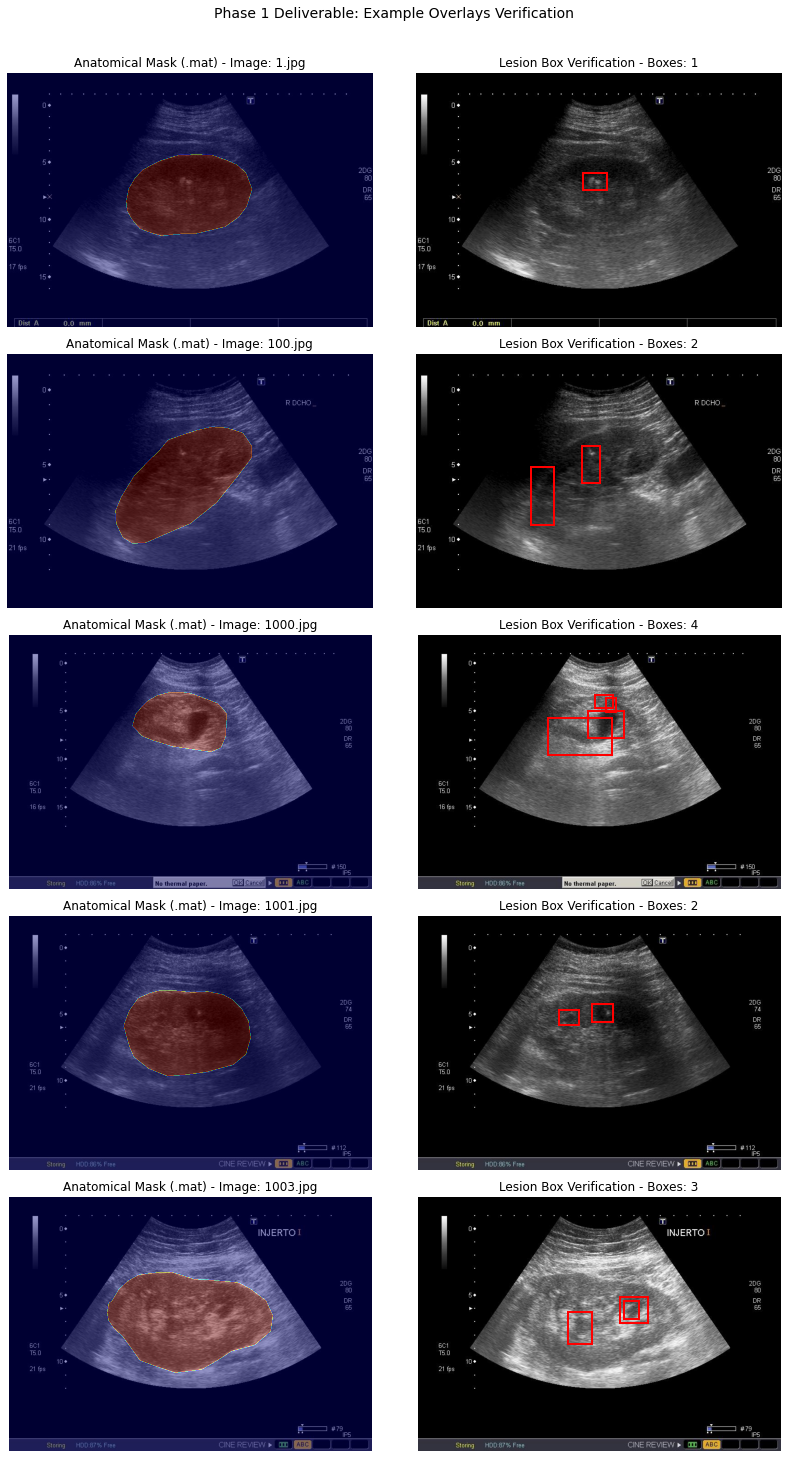

Successfully verified 5 distinct image overlays for Phase 1 deliverables.


In [ ]:
import os
import scipy.io as sio
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# 1. Buscar hasta 5 imágenes distintas que tengan Bounding Boxes de lesión
sample_cases = []

labels_dir = os.path.join('bbdd_kidney', 'labels')
if os.path.exists(labels_dir):
    for label_file in sorted(os.listdir(labels_dir)):
        if label_file.endswith('.txt'):
            path = os.path.join(labels_dir, label_file)
            with open(path, 'r', encoding='utf-8', errors='replace') as f:
                lines = f.readlines()
                current_boxes = []
                for line in lines:
                    line_clean = line.strip()
                    if "bounding box" in line_clean.lower():
                        import re
                        numbers = [int(n) for n in re.findall(r'\d+', line_clean)]
                        if len(numbers) >= 5:
                            x, y, w, h, cls = numbers[-5:]
                            current_boxes.append((x, y, w, h, cls))
                
                if len(current_boxes) > 0:
                    img_id = label_file.replace('.txt', '')
                    sample_cases.append((img_id, current_boxes))
                    if len(sample_cases) == 5:  # Obtener 5 ejemplos representativos
                        break

# 2. Renderizar grid con múltiples ejemplos (Example overlays)
num_samples = len(sample_cases)

if num_samples > 0:
    fig, axes = plt.subplots(num_samples, 2, figsize=(12, 4 * num_samples))
    if num_samples == 1:
        axes = [axes]  # Mantener estructura 2D si solo hay 1

    for idx, (img_id, boxes) in enumerate(sample_cases):
        img_name = f"{img_id}.jpg"
        img_path = os.path.join('bbdd_kidney', 'images', img_name)
        mask_path = os.path.join('bbdd_kidney', 'masks', f"{img_id}.mat")

        if os.path.exists(img_path) and os.path.exists(mask_path):
            img = Image.open(img_path).convert('RGB')
            mat_data = sio.loadmat(mask_path)
            valid_keys = [k for k in mat_data.keys() if not k.startswith('__')]

            # Subplot Izquierdo: Máscara anatómica (.mat)
            axes[idx][0].imshow(img)
            if len(valid_keys) > 0:
                mask_matrix = mat_data[valid_keys[0]]
                axes[idx][0].imshow(mask_matrix, alpha=0.4, cmap='jet')
            axes[idx][0].set_title(f"Anatomical Mask (.mat) - Image: {img_name}")
            axes[idx][0].axis('off')

            # Subplot Derecho: Cajas de lesión (.txt)
            axes[idx][1].imshow(img)
            for (x, y, w, h, cls) in boxes:
                rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='r', facecolor='none')
                axes[idx][1].add_patch(rect)
            axes[idx][1].set_title(f"Lesion Box Verification - Boxes: {len(boxes)}")
            axes[idx][1].axis('off')

    plt.suptitle("Phase 1 Deliverable: Example Overlays Verification", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()
    print(f"Successfully verified {num_samples} distinct image overlays for Phase 1 deliverables.")
else:
    print(" Check path: No labels found in 'bbdd_kidney/labels'")